In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler, LabelEncoder
from scipy.stats import pointbiserialr
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
import warnings
import math

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("./heart.csv")

In [3]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [6]:
df.columns = df.columns.str.lower()

In [7]:
df.columns

Index(['age', 'sex', 'chestpaintype', 'restingbp', 'cholesterol', 'fastingbs',
       'restingecg', 'maxhr', 'exerciseangina', 'oldpeak', 'st_slope',
       'heartdisease'],
      dtype='str')

In [8]:
df.head()

,age,sex,chestpaintype,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [9]:
df["chestpaintype"].value_counts()

chestpaintype
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64

In [10]:
df = pd.get_dummies(data=df, columns=["chestpaintype"], dtype=int)

In [11]:
df.head()

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
0,40,M,140,289,0,Normal,172,N,0.0,Up,0,0,1,0,0
1,49,F,160,180,0,Normal,156,N,1.0,Flat,1,0,0,1,0
2,37,M,130,283,0,ST,98,N,0.0,Up,0,0,1,0,0
3,48,F,138,214,0,Normal,108,Y,1.5,Flat,1,1,0,0,0
4,54,M,150,195,0,Normal,122,N,0.0,Up,0,0,0,1,0


In [12]:
df["exerciseangina"].value_counts()

exerciseangina
N    547
Y    371
Name: count, dtype: int64

In [13]:
df["exerciseangina"].isnull().sum()

np.int64(0)

In [14]:
df.isnull().sum()

age                  0
sex                  0
restingbp            0
cholesterol          0
fastingbs            0
restingecg           0
maxhr                0
exerciseangina       0
oldpeak              0
st_slope             0
heartdisease         0
chestpaintype_ASY    0
chestpaintype_ATA    0
chestpaintype_NAP    0
chestpaintype_TA     0
dtype: int64

In [15]:
df.head()

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
0,40,M,140,289,0,Normal,172,N,0.0,Up,0,0,1,0,0
1,49,F,160,180,0,Normal,156,N,1.0,Flat,1,0,0,1,0
2,37,M,130,283,0,ST,98,N,0.0,Up,0,0,1,0,0
3,48,F,138,214,0,Normal,108,Y,1.5,Flat,1,1,0,0,0
4,54,M,150,195,0,Normal,122,N,0.0,Up,0,0,0,1,0


<Axes: xlabel='restingbp', ylabel='Count'>

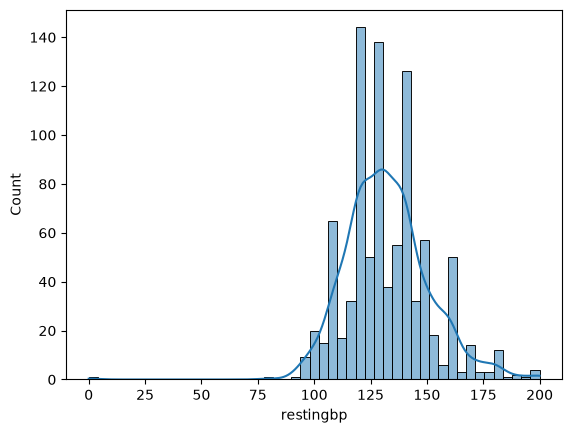

In [16]:
sns.histplot(df["restingbp"], kde=True)

In [17]:
df[df["restingbp"] == 0]

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
449,55,M,0,0,0,Normal,155,N,1.5,Flat,1,0,0,1,0


In [18]:
indices_to_drop = df[df["restingbp"] == 0].index
df.drop(indices_to_drop, inplace=True)

In [19]:
df[df["restingbp"] == 0]

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA


<Axes: xlabel='restingbp', ylabel='Count'>

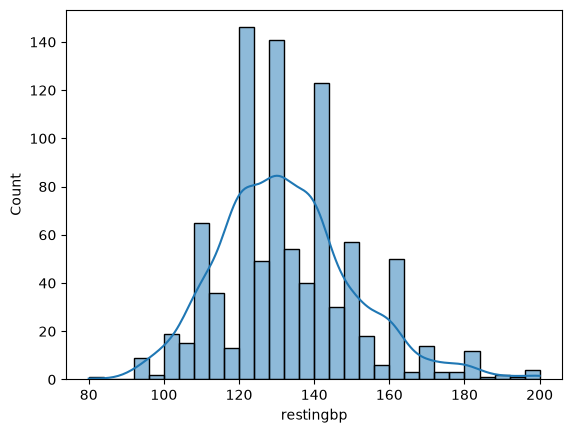

In [20]:
sns.histplot(df["restingbp"], kde=True)

In [21]:
df["restingbp"].isnull().sum()

np.int64(0)

In [22]:
scaler = StandardScaler()
df[["restingbp"]] = scaler.fit_transform(df[["restingbp"]])

In [23]:
df["restingbp"].head()

0    0.414627
1    1.526360
2   -0.141240
3    0.303453
4    0.970493
Name: restingbp, dtype: float64

<Axes: xlabel='restingbp', ylabel='Count'>

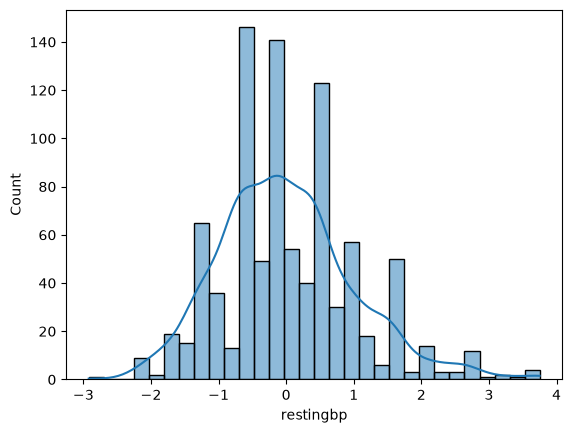

In [24]:
sns.histplot(df["restingbp"], kde=True)

In [25]:
df["cholesterol"].head()

0    289
1    180
2    283
3    214
4    195
Name: cholesterol, dtype: int64

<Axes: xlabel='cholesterol', ylabel='Count'>

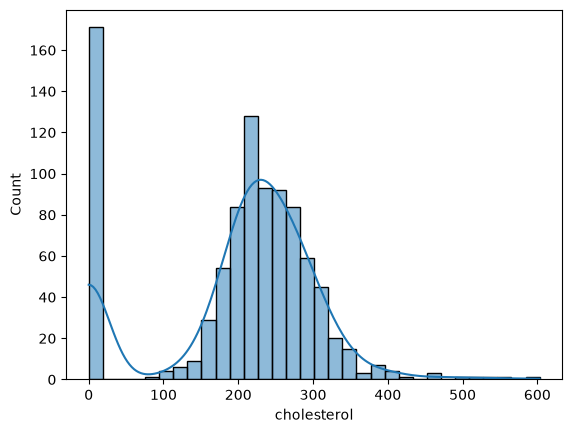

In [26]:
sns.histplot(df["cholesterol"], kde=True)

In [27]:
indices_to_drop = df[df["cholesterol"] == 0].index
df.drop(indices_to_drop, inplace=True)

<Axes: xlabel='cholesterol', ylabel='Count'>

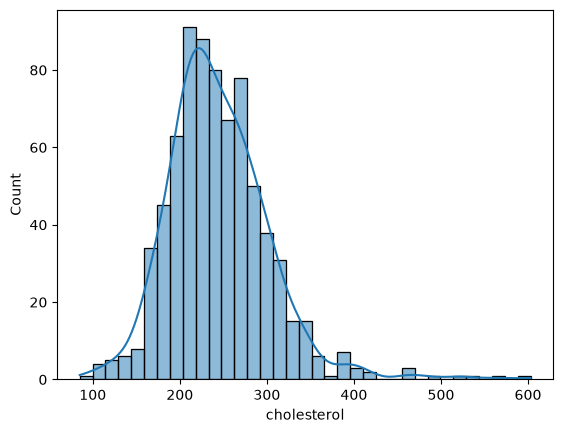

In [28]:
sns.histplot(df["cholesterol"], kde=True)

In [29]:
df[["cholesterol"]] = scaler.fit_transform(df[["cholesterol"]])

<Axes: xlabel='cholesterol', ylabel='Count'>

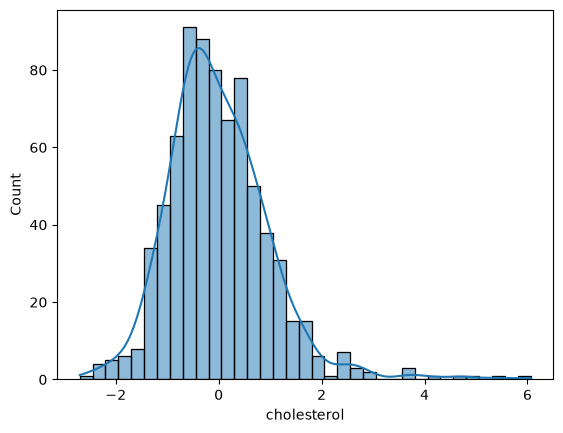

In [30]:
sns.histplot(df["cholesterol"], kde=True)

In [31]:
df.head()

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
0,40,M,0.414627,0.750494,0,Normal,172,N,0.0,Up,0,0,1,0,0
1,49,F,1.526360,-1.093405,0,Normal,156,N,1.0,Flat,1,0,0,1,0
2,37,M,-0.141240,0.648995,0,ST,98,N,0.0,Up,0,0,1,0,0
3,48,F,0.303453,-0.518244,0,Normal,108,Y,1.5,Flat,1,1,0,0,0
4,54,M,0.970493,-0.839657,0,Normal,122,N,0.0,Up,0,0,0,1,0


In [32]:
encoder = LabelEncoder()
df["restingecg"] = encoder.fit_transform(df["restingecg"])

In [33]:
df.head()

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
0,40,M,0.414627,0.750494,0,1,172,N,0.0,Up,0,0,1,0,0
1,49,F,1.526360,-1.093405,0,1,156,N,1.0,Flat,1,0,0,1,0
2,37,M,-0.141240,0.648995,0,2,98,N,0.0,Up,0,0,1,0,0
3,48,F,0.303453,-0.518244,0,1,108,Y,1.5,Flat,1,1,0,0,0
4,54,M,0.970493,-0.839657,0,1,122,N,0.0,Up,0,0,0,1,0


In [34]:
df["maxhr"].value_counts()

maxhr
150    39
140    37
130    27
160    24
120    21
       ..
195     1
95      1
194     1
187     1
202     1
Name: count, Length: 109, dtype: int64

<Axes: xlabel='maxhr', ylabel='Count'>

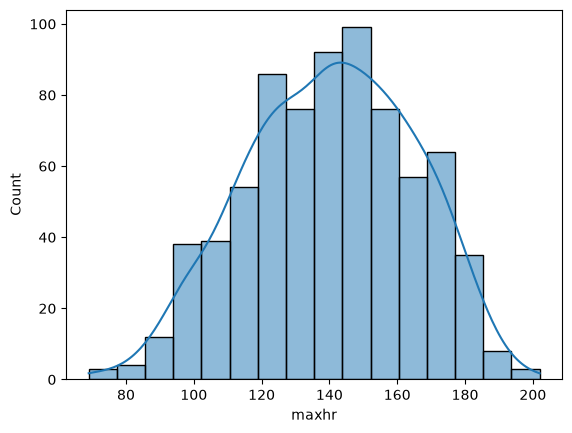

In [35]:
sns.histplot(df["maxhr"], kde=True)

In [36]:
df.head()

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
0,40,M,0.414627,0.750494,0,1,172,N,0.0,Up,0,0,1,0,0
1,49,F,1.526360,-1.093405,0,1,156,N,1.0,Flat,1,0,0,1,0
2,37,M,-0.141240,0.648995,0,2,98,N,0.0,Up,0,0,1,0,0
3,48,F,0.303453,-0.518244,0,1,108,Y,1.5,Flat,1,1,0,0,0
4,54,M,0.970493,-0.839657,0,1,122,N,0.0,Up,0,0,0,1,0


In [37]:
df[["maxhr"]] = scaler.fit_transform(df[["maxhr"]])

In [38]:
df["maxhr"].isnull().sum()

np.int64(0)

In [39]:
df.head()

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
0,40,M,0.414627,0.750494,0,1,1.296470,N,0.0,Up,0,0,1,0,0
1,49,F,1.526360,-1.093405,0,1,0.643613,N,1.0,Flat,1,0,0,1,0
2,37,M,-0.141240,0.648995,0,2,-1.722993,N,0.0,Up,0,0,1,0,0
3,48,F,0.303453,-0.518244,0,1,-1.314958,Y,1.5,Flat,1,1,0,0,0
4,54,M,0.970493,-0.839657,0,1,-0.743708,N,0.0,Up,0,0,0,1,0


<Axes: xlabel='maxhr', ylabel='Count'>

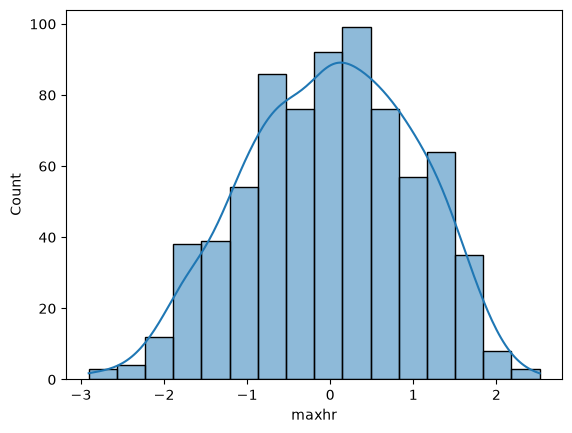

In [40]:
sns.histplot(df["maxhr"], kde=True)

In [41]:
df["exerciseangina"].isnull().sum()

np.int64(0)

In [42]:
df["exerciseangina"] = encoder.fit_transform(df["exerciseangina"])

In [43]:
df["oldpeak"].isnull().sum()

np.int64(0)

In [44]:
df["oldpeak"].value_counts()

oldpeak
 0.0    317
 1.0     68
 2.0     58
 1.5     39
 3.0     23
 1.2     22
 0.2     19
 0.8     15
 1.4     15
 1.8     15
 0.6     14
 1.6     13
 0.5     12
 2.5     11
 0.1     10
 0.4     10
 0.3      9
 4.0      8
 1.9      7
 2.6      6
 2.8      6
 1.3      5
 1.7      5
 1.1      4
 2.2      4
 3.6      4
 2.4      3
 3.4      3
 0.9      3
 3.5      2
 2.3      2
 4.2      2
 3.2      2
 5.0      1
-0.1      1
 3.1      1
 0.7      1
 5.6      1
 3.8      1
 2.1      1
 2.9      1
 6.2      1
 4.4      1
Name: count, dtype: int64

In [45]:
df[["oldpeak"]] = scaler.fit_transform(df[["oldpeak"]])

<Axes: xlabel='oldpeak', ylabel='Count'>

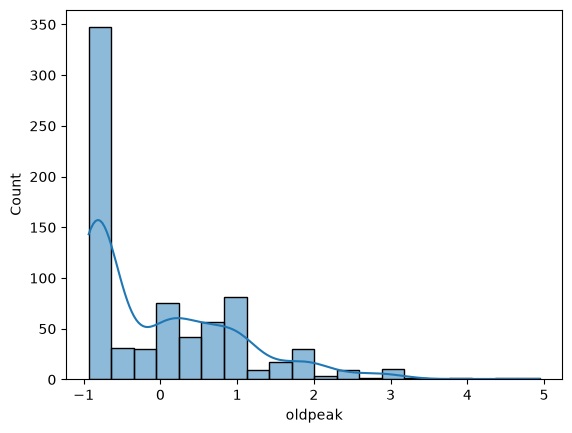

In [46]:
sns.histplot(df["oldpeak"], kde=True)

In [47]:
df.head()

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
0,40,M,0.414627,0.750494,0,1,1.296470,0,-0.840942,Up,0,0,1,0,0
1,49,F,1.526360,-1.093405,0,1,0.643613,0,0.091771,Flat,1,0,0,1,0
2,37,M,-0.141240,0.648995,0,2,-1.722993,0,-0.840942,Up,0,0,1,0,0
3,48,F,0.303453,-0.518244,0,1,-1.314958,1,0.558127,Flat,1,1,0,0,0
4,54,M,0.970493,-0.839657,0,1,-0.743708,0,-0.840942,Up,0,0,0,1,0


In [48]:
df["st_slope"].value_counts()

st_slope
Flat    354
Up      349
Down     43
Name: count, dtype: int64

In [49]:
df["st_slope"].isnull().sum()

np.int64(0)

In [50]:
df["st_slope"] = encoder.fit_transform(df["st_slope"])

<Axes: xlabel='st_slope', ylabel='Count'>

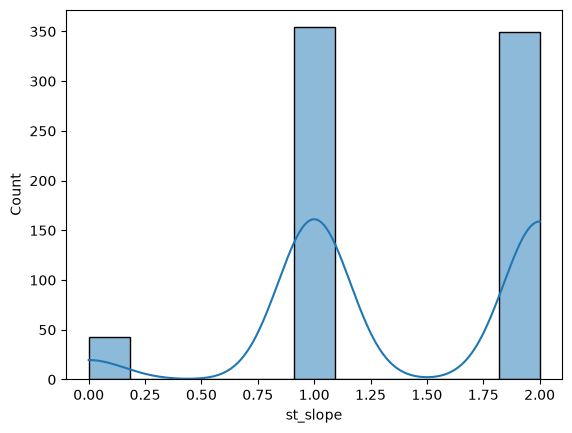

In [51]:
sns.histplot(df["st_slope"], kde=True)

In [52]:
df["exerciseangina"].isnull().sum()

np.int64(0)

In [53]:
df["exerciseangina"].value_counts()

exerciseangina
0    459
1    287
Name: count, dtype: int64

<Axes: xlabel='exerciseangina', ylabel='Count'>

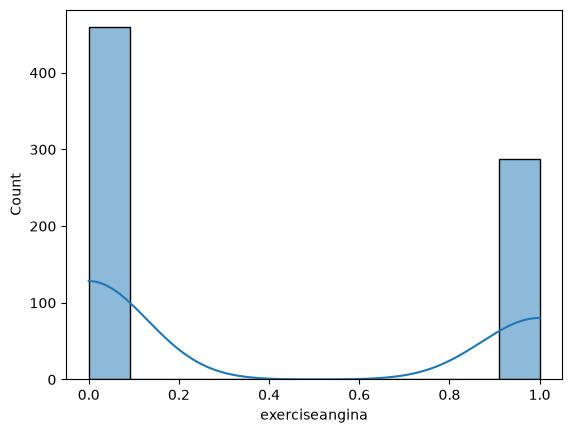

In [54]:
sns.histplot(df["exerciseangina"], kde=True)

In [55]:
df["exerciseangina"] = encoder.fit_transform(df["exerciseangina"])

In [56]:
df.head()

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
0,40,M,0.414627,0.750494,0,1,1.296470,0,-0.840942,2,0,0,1,0,0
1,49,F,1.526360,-1.093405,0,1,0.643613,0,0.091771,1,1,0,0,1,0
2,37,M,-0.141240,0.648995,0,2,-1.722993,0,-0.840942,2,0,0,1,0,0
3,48,F,0.303453,-0.518244,0,1,-1.314958,1,0.558127,1,1,1,0,0,0
4,54,M,0.970493,-0.839657,0,1,-0.743708,0,-0.840942,2,0,0,0,1,0


In [57]:
df["sex"].value_counts()

sex
M    564
F    182
Name: count, dtype: int64

In [58]:
df["sex"].isnull().sum()

np.int64(0)

In [59]:
df["sex"] = encoder.fit_transform(df["sex"])

In [60]:
df.info()

<class 'pandas.DataFrame'>
Index: 746 entries, 0 to 917
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                746 non-null    int64  
 1   sex                746 non-null    int64  
 2   restingbp          746 non-null    float64
 3   cholesterol        746 non-null    float64
 4   fastingbs          746 non-null    int64  
 5   restingecg         746 non-null    int64  
 6   maxhr              746 non-null    float64
 7   exerciseangina     746 non-null    int64  
 8   oldpeak            746 non-null    float64
 9   st_slope           746 non-null    int64  
 10  heartdisease       746 non-null    int64  
 11  chestpaintype_ASY  746 non-null    int64  
 12  chestpaintype_ATA  746 non-null    int64  
 13  chestpaintype_NAP  746 non-null    int64  
 14  chestpaintype_TA   746 non-null    int64  
dtypes: float64(4), int64(11)
memory usage: 93.2 KB


In [61]:
df[["age"]] = scaler.fit_transform(df[['age']])

In [62]:
df.columns

Index(['age', 'sex', 'restingbp', 'cholesterol', 'fastingbs', 'restingecg',
       'maxhr', 'exerciseangina', 'oldpeak', 'st_slope', 'heartdisease',
       'chestpaintype_ASY', 'chestpaintype_ATA', 'chestpaintype_NAP',
       'chestpaintype_TA'],
      dtype='str')

<Axes: xlabel='age', ylabel='Count'>

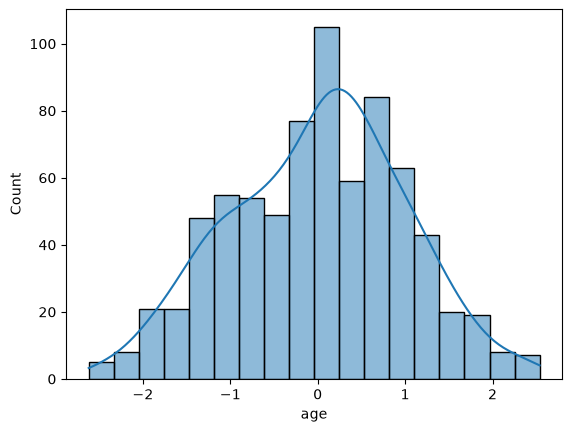

In [63]:
sns.histplot(df["age"], kde=True)

In [64]:
df["heartdisease"].corr(df["age"])

np.float64(0.29861668487267484)

In [65]:
df.head()

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
0,-1.356073,1,0.414627,0.750494,0,1,1.296470,0,-0.840942,2,0,0,1,0,0
1,-0.408656,0,1.526360,-1.093405,0,1,0.643613,0,0.091771,1,1,0,0,1,0
2,-1.671879,1,-0.141240,0.648995,0,2,-1.722993,0,-0.840942,2,0,0,1,0,0
3,-0.513925,0,0.303453,-0.518244,0,1,-1.314958,1,0.558127,1,1,1,0,0,0
4,0.117686,1,0.970493,-0.839657,0,1,-0.743708,0,-0.840942,2,0,0,0,1,0


<Axes: xlabel='heartdisease', ylabel='age'>

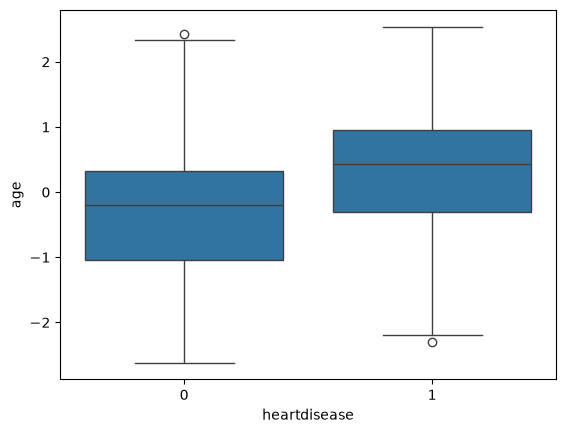

In [66]:
sns.boxplot(data=df, x="heartdisease", y="age")

In [67]:
r_pb, p_value = pointbiserialr(df["heartdisease"], df["age"])

In [68]:
alpha = 0.05

In [69]:
df.head()

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
0,-1.356073,1,0.414627,0.750494,0,1,1.296470,0,-0.840942,2,0,0,1,0,0
1,-0.408656,0,1.526360,-1.093405,0,1,0.643613,0,0.091771,1,1,0,0,1,0
2,-1.671879,1,-0.141240,0.648995,0,2,-1.722993,0,-0.840942,2,0,0,1,0,0
3,-0.513925,0,0.303453,-0.518244,0,1,-1.314958,1,0.558127,1,1,1,0,0,0
4,0.117686,1,0.970493,-0.839657,0,1,-0.743708,0,-0.840942,2,0,0,0,1,0


In [70]:
cols = ["age", "restingbp", "cholesterol", "maxhr", "oldpeak"]
point_biserial_correlation = {}
for col in cols:
  r_pb, p_value = pointbiserialr(df["heartdisease"], df[col])
  message = "Reject null hypothesis" if p_value <= alpha else "Fail to reject null hypothesis"
  point_biserial_correlation[col] = {
    "p_value": p_value,
    "r_pb": r_pb,
    "message": message
  }
point_biserial_correlation

{'age': {'p_value': np.float64(7.861071765823028e-17),
  'r_pb': np.float64(0.29861668487267473),
  'message': 'Reject null hypothesis'},
 'restingbp': {'p_value': np.float64(1.937383624038602e-06),
  'r_pb': np.float64(0.1732415815501214),
  'message': 'Reject null hypothesis'},
 'cholesterol': {'p_value': np.float64(0.004514069106741906),
  'r_pb': np.float64(0.10386559562465619),
  'message': 'Reject null hypothesis'},
 'maxhr': {'p_value': np.float64(1.2269260081360141e-26),
  'r_pb': np.float64(-0.37721219001674394),
  'message': 'Reject null hypothesis'},
 'oldpeak': {'p_value': np.float64(1.6302939711725656e-47),
  'r_pb': np.float64(0.4956962549378717),
  'message': 'Reject null hypothesis'}}

In [71]:
df.head()

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
0,-1.356073,1,0.414627,0.750494,0,1,1.296470,0,-0.840942,2,0,0,1,0,0
1,-0.408656,0,1.526360,-1.093405,0,1,0.643613,0,0.091771,1,1,0,0,1,0
2,-1.671879,1,-0.141240,0.648995,0,2,-1.722993,0,-0.840942,2,0,0,1,0,0
3,-0.513925,0,0.303453,-0.518244,0,1,-1.314958,1,0.558127,1,1,1,0,0,0
4,0.117686,1,0.970493,-0.839657,0,1,-0.743708,0,-0.840942,2,0,0,0,1,0


In [72]:
df["sex"].value_counts()

sex
1    564
0    182
Name: count, dtype: int64

In [73]:
df["fastingbs"].value_counts()

fastingbs
0    621
1    125
Name: count, dtype: int64

In [74]:
df["restingecg"].value_counts()

restingecg
1    445
0    176
2    125
Name: count, dtype: int64

In [75]:
df["exerciseangina"].value_counts()

exerciseangina
0    459
1    287
Name: count, dtype: int64

In [76]:
qualitative_cols = ["sex", "fastingbs", "restingecg", "exerciseangina", "st_slope", "chestpaintype_ASY", "chestpaintype_ATA", "chestpaintype_NAP", "chestpaintype_TA"]
qualitative_chi2_correlation = {}
min_val = 0.1
for col in qualitative_cols:
  contingency_table = pd.crosstab(df["heartdisease"], df[col])
  chi2_stats, p_value, dof, expected_freq = stats.chi2_contingency(contingency_table)
  n = contingency_table.sum().sum()
  min_dim = min(contingency_table.shape) - 1
  cramers_v = math.sqrt((chi2_stats / (n * min_dim)))
  if cramers_v >= min_val:
    qualitative_chi2_correlation[col] = {
      "cramers_v": cramers_v,
    }
qualitative_chi2_correlation

{'sex': {'cramers_v': 0.28965423399948864},
 'fastingbs': {'cramers_v': 0.15700115619114782},
 'restingecg': {'cramers_v': 0.13610643383556348},
 'exerciseangina': {'cramers_v': 0.5490764359422066},
 'st_slope': {'cramers_v': 0.6540630106149249},
 'chestpaintype_ASY': {'cramers_v': 0.5202981485694289},
 'chestpaintype_ATA': {'cramers_v': 0.3724075042732047},
 'chestpaintype_NAP': {'cramers_v': 0.21894026090946547}}

In [77]:
cols = ["age", "restingbp", "cholesterol", "maxhr", "oldpeak", "sex", "fastingbs", "restingecg", "exerciseangina", "st_slope", "chestpaintype_ASY", "chestpaintype_ATA", "chestpaintype_NAP"]
selected_features_df = df[cols]
output_feature = df["heartdisease"]
selected_features_df.head()

,age,restingbp,cholesterol,maxhr,oldpeak,sex,fastingbs,restingecg,exerciseangina,st_slope,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP
0,-1.356073,0.414627,0.750494,1.296470,-0.840942,1,0,1,0,2,0,1,0
1,-0.408656,1.526360,-1.093405,0.643613,0.091771,0,0,1,0,1,0,0,1
2,-1.671879,-0.141240,0.648995,-1.722993,-0.840942,1,0,2,0,2,0,1,0
3,-0.513925,0.303453,-0.518244,-1.314958,0.558127,0,0,1,1,1,1,0,0
4,0.117686,0.970493,-0.839657,-0.743708,-0.840942,1,0,1,0,2,0,0,1


In [78]:
X_train, X_test, y_train, y_test = train_test_split(selected_features_df, output_feature, random_state=42, test_size=0.2)

In [79]:
y_test

208    0
259    0
97     0
148    0
567    1
      ..
726    0
69     0
694    0
131    1
44     1
Name: heartdisease, Length: 150, dtype: int64

In [80]:
logistic_reg_model = LogisticRegression()
logistic_reg_model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [81]:
y_predict_log_reg = logistic_reg_model.predict(X_test)

In [82]:
confusion_matrix(y_predict_log_reg, y_test)

array([[63, 13],
       [ 8, 66]])

In [83]:
accuracy_score(y_predict_log_reg, y_test)

0.86

In [84]:
f1_score(y_predict_log_reg, y_test)

0.8627450980392157

In [85]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [86]:
knn_model_predict = knn_model.predict(X_test)

In [87]:
confusion_matrix(knn_model_predict, y_test)

array([[62, 14],
       [ 9, 65]])

In [88]:
accuracy_score(knn_model_predict, y_test)

0.8466666666666667

In [89]:
df.head()

,age,sex,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,chestpaintype_ASY,chestpaintype_ATA,chestpaintype_NAP,chestpaintype_TA
0,-1.356073,1,0.414627,0.750494,0,1,1.296470,0,-0.840942,2,0,0,1,0,0
1,-0.408656,0,1.526360,-1.093405,0,1,0.643613,0,0.091771,1,1,0,0,1,0
2,-1.671879,1,-0.141240,0.648995,0,2,-1.722993,0,-0.840942,2,0,0,1,0,0
3,-0.513925,0,0.303453,-0.518244,0,1,-1.314958,1,0.558127,1,1,1,0,0,0
4,0.117686,1,0.970493,-0.839657,0,1,-0.743708,0,-0.840942,2,0,0,0,1,0


In [91]:
X = df.drop('heartdisease', axis=1)
Y = df["heartdisease"]

In [92]:
from sklearn.model_selection import cross_val_score

In [94]:
score = cross_val_score(knn_model, X=X, y=Y, cv=5, scoring="accuracy")

In [95]:
score

array([0.84      , 0.87919463, 0.87248322, 0.75167785, 0.81208054])

In [96]:
score.mean()

np.float64(0.8310872483221475)